In [1]:
import numpy as np
import pandas as pd
import os
from pathlib import Path
import matplotlib.pyplot as plt

import import_ipynb

curdir = os.getcwd()
src_path = Path('../src/')
os.chdir(src_path)
from BaseDataSet_Gen import NanoparticleDataFactory, plot_cn_distribution, plot_dataset_variability
os.chdir(curdir)

## Загрузим данные и определим необходимые пути

In [2]:
SPECTRA_ROOT = Path('../processed_data/conv_dense_spectra/')

FIG_SAVE_PATH = Path('../images/')
N_SAMPLES = 30000

UNIQUE_SUBSTRUCTURES = pd.read_pickle('../source_data/INIT_unique_substructures_Rcut_7.5_stephist_0.1.pkl')
UNIQUE_SUBSTRUCTURES.head(3)

,Structure,Num_atoms,CN
0,"(Atom('Pt', [np.float64(0.0), np.float64(0.0),...",18,"[4.0, 1.0, 4.0, 4.0, 4.0, 0.0, 0.0]"
1,"(Atom('Pt', [np.float64(0.0), np.float64(0.0),...",46,"[6.0, 3.0, 9.0, 4.0, 9.0, 2.0, 12.0]"
2,"(Atom('Pt', [np.float64(0.0), np.float64(0.0),...",46,"[8.0, 5.0, 12.0, 4.0, 4.0, 4.0, 8.0]"


## Проверка влияния Kmix на распределение CN внутри DataSet'а

In [3]:
# Инициализация фабрики
e_grid = np.arange(-10, 100.1, 0.5) # Задаем сетку энергии для XANES спектров
factory = NanoparticleDataFactory(energy_grid=e_grid)

In [4]:
# Загрузка базиса
# Мы извлекаем CN для 7 сфер и интерполируем спектры
factory.load_basis(spectra_dir=SPECTRA_ROOT, 
                   substruct_df=UNIQUE_SUBSTRUCTURES, 
                   n_spheres=7 # Контроль кол-ва сфер.
                  )


Готово. В базисе 2151 подструктур.


### Kmix=2

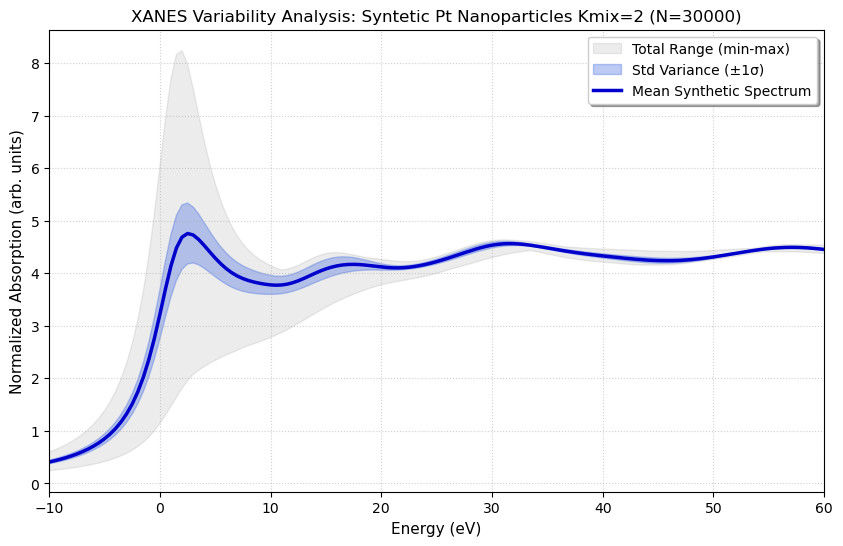

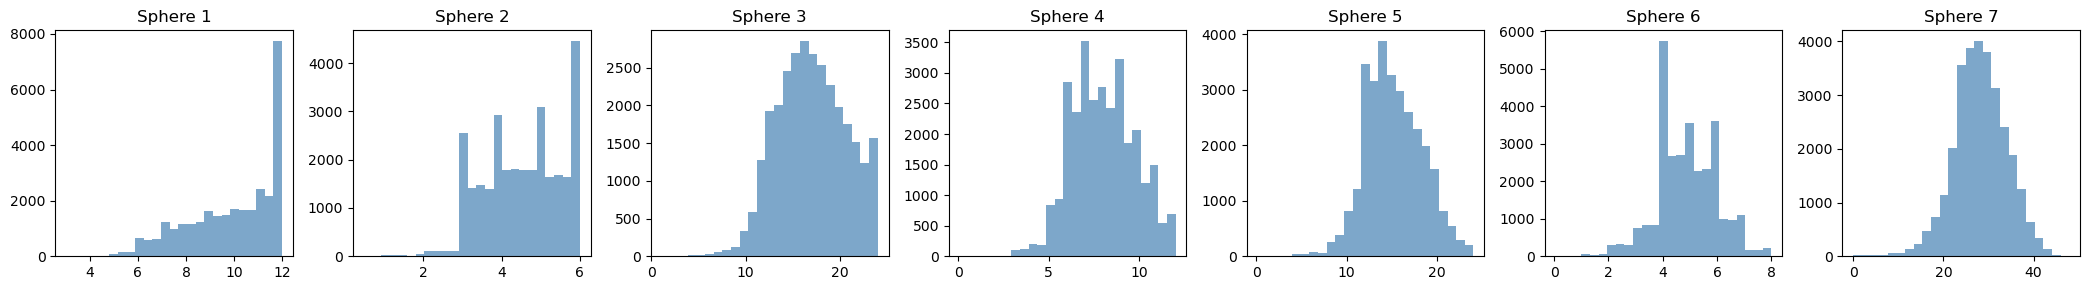

CPU times: total: 12.4 s
Wall time: 7.91 s


In [5]:
%%time
# Генерируем N_SAMPLES синтетических образцов (замешиваем по Kmix подструктур)
K_mix=2
save_name_cn = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_CN'))
save_name_spec = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_Spectra_var'))
train_weights = factory.create_synthetic_mix(n_samples=N_SAMPLES, 
                                             k_range=(K_mix, K_mix), 
                                             pool_indices=None)

# Получаем X-спектры и y-векторы CN по 7 сферам
# аугментации спектров не применяются.
X_km, y_km = factory.generate_experiment_data(train_weights, aug_params=None)

# Отрисуем вариантивность спектров при такой генерации.
plot_dataset_variability(X_data=X_km, 
                         energy_grid=factory.energy_grid,
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Syntetic Pt Nanoparticles Kmix={K_mix}", 
                         save_name=save_name_spec
                        )

plot_cn_distribution(y_matrix=y_km, save_name=save_name_cn)

### Kmix=3 (как в работе J.Timoshenko 2017)

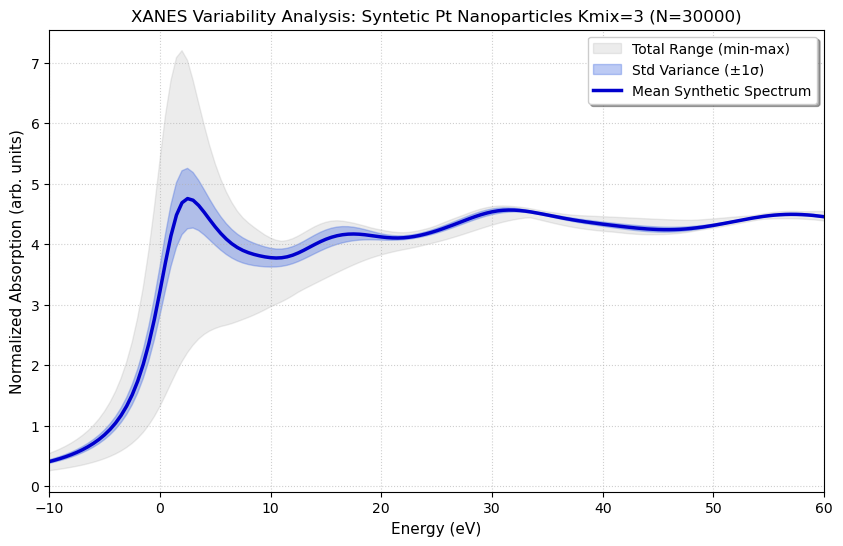

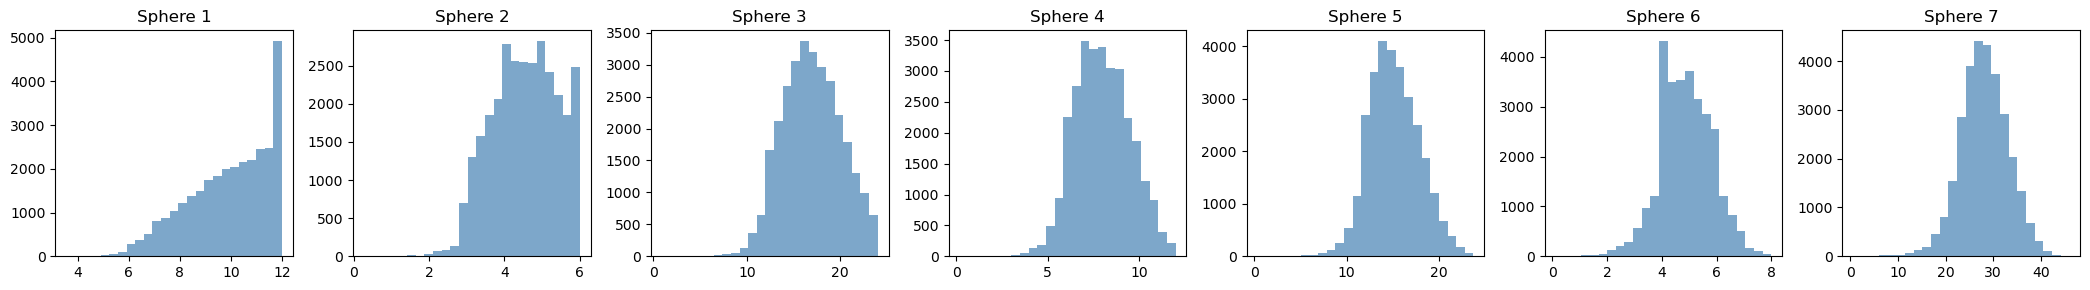

CPU times: total: 15.5 s
Wall time: 8.61 s


In [6]:
%%time
K_mix=3
save_name_cn = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_CN'))
save_name_spec = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_Spectra_var'))
train_weights = factory.create_synthetic_mix(n_samples=N_SAMPLES, 
                                             k_range=(K_mix, K_mix), 
                                             pool_indices=None)

X_km, y_km = factory.generate_experiment_data(train_weights, aug_params=None)

plot_dataset_variability(X_data=X_km, 
                         energy_grid=factory.energy_grid,
                         foil_spectrum=None, # Опционально 
                         title_suffix=f"Syntetic Pt Nanoparticles Kmix={K_mix}", 
                         save_name=save_name_spec
                        )

plot_cn_distribution(y_matrix=y_km, save_name=save_name_cn)

### Kmix=4

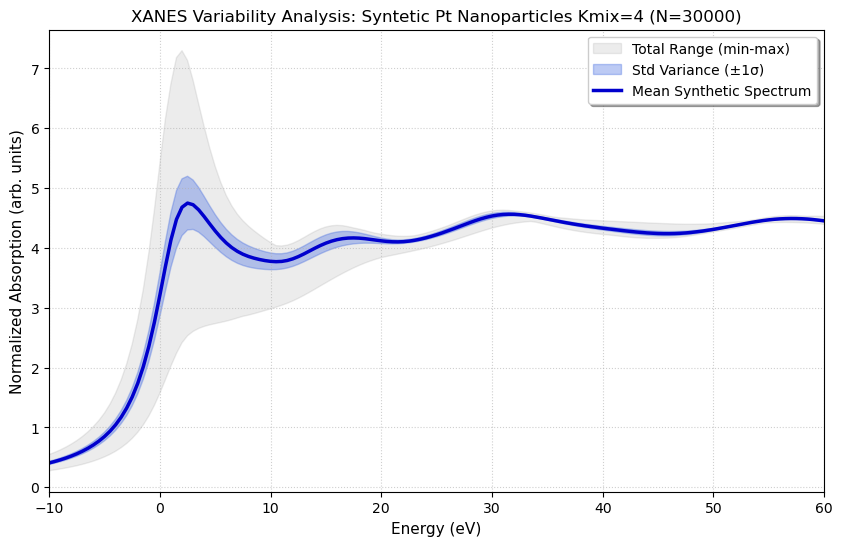

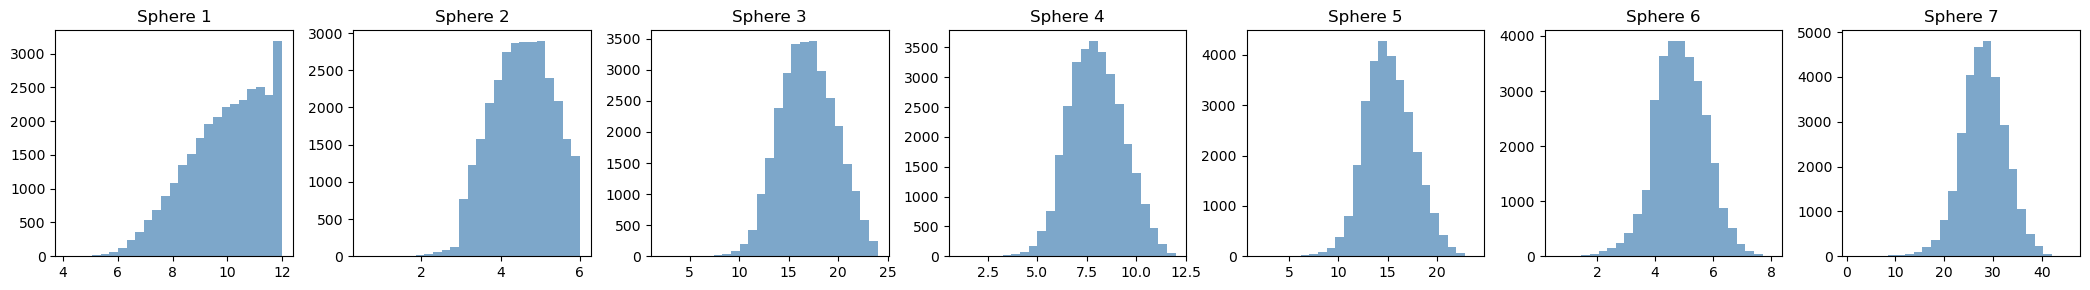

CPU times: total: 15.1 s
Wall time: 8.64 s


In [7]:
%%time

K_mix=4
save_name_cn = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_CN'))
save_name_spec = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_Spectra_var'))
train_weights = factory.create_synthetic_mix(n_samples=N_SAMPLES, 
                                             k_range=(K_mix, K_mix), 
                                             pool_indices=None)

X_km, y_km = factory.generate_experiment_data(train_weights, aug_params=None)

plot_dataset_variability(X_data=X_km, 
                         energy_grid=factory.energy_grid,
                         foil_spectrum=None,
                         title_suffix=f"Syntetic Pt Nanoparticles Kmix={K_mix}", 
                         save_name=save_name_spec
                        )

plot_cn_distribution(y_matrix=y_km, save_name=save_name_cn)

### Kmix=5

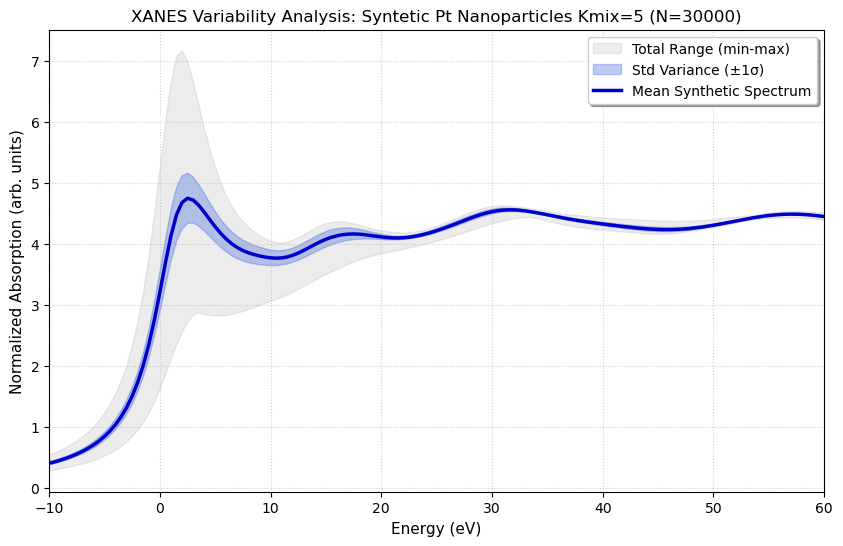

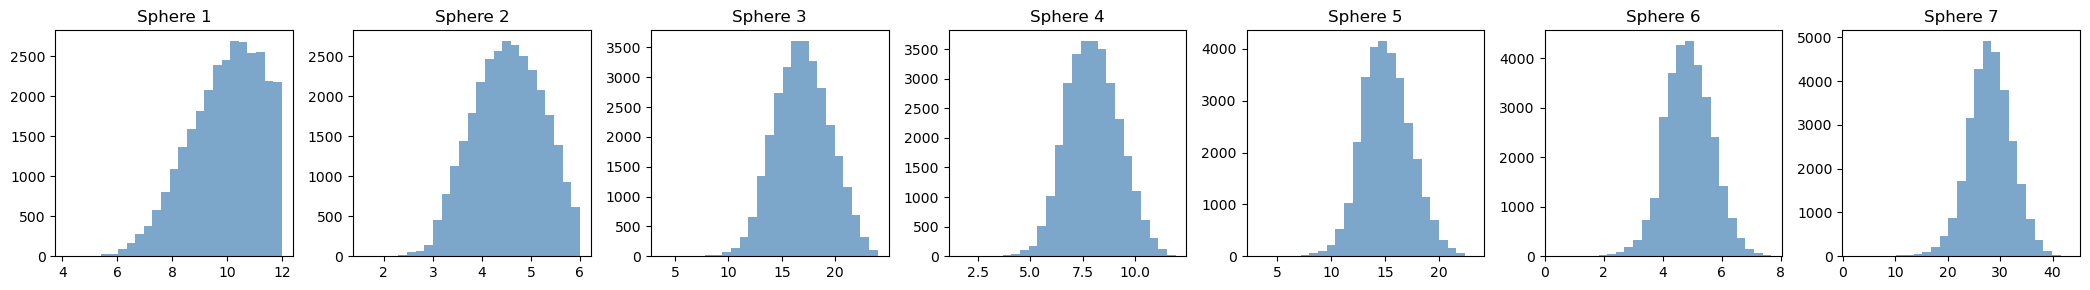

CPU times: total: 14.5 s
Wall time: 8.46 s


In [8]:
%%time

K_mix=5
save_name_cn = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_CN'))
save_name_spec = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_Spectra_var'))
train_weights = factory.create_synthetic_mix(n_samples=N_SAMPLES, 
                                             k_range=(K_mix, K_mix), 
                                             pool_indices=None)

X_km, y_km = factory.generate_experiment_data(train_weights, aug_params=None)

plot_dataset_variability(X_data=X_km, 
                         energy_grid=factory.energy_grid,
                         foil_spectrum=None,
                         title_suffix=f"Syntetic Pt Nanoparticles Kmix={K_mix}", 
                         save_name=save_name_spec
                        )

plot_cn_distribution(y_matrix=y_km, save_name=save_name_cn)

### Kmix (2-10)

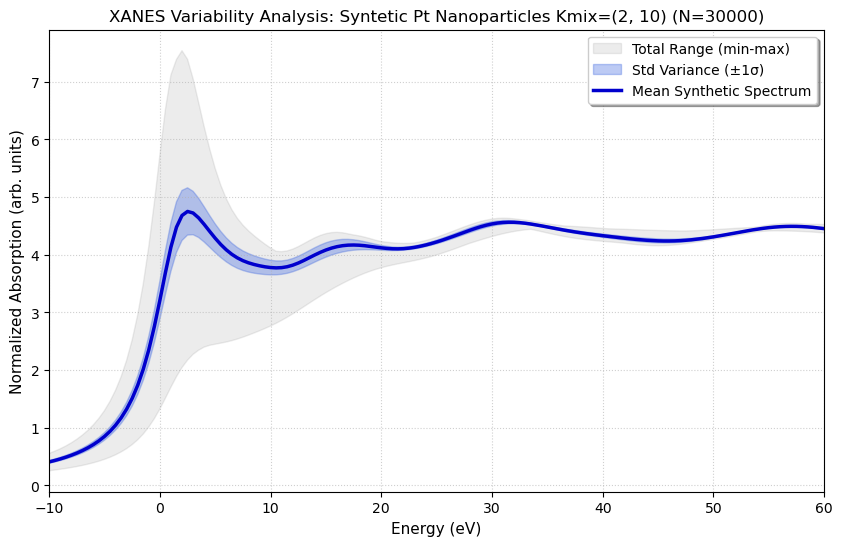

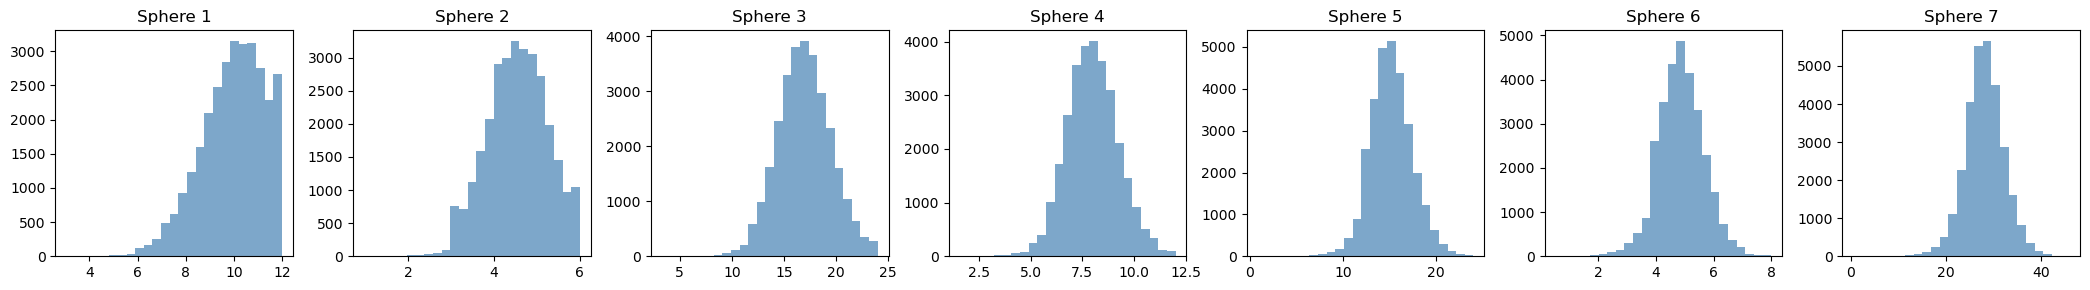

CPU times: total: 15.7 s
Wall time: 8.64 s


In [9]:
%%time

K_mix=(2,10)
save_name_cn = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_CN'))
save_name_spec = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_Spectra_var'))
train_weights = factory.create_synthetic_mix(n_samples=N_SAMPLES, 
                                             k_range=K_mix, 
                                             pool_indices=None)

X_km, y_km = factory.generate_experiment_data(train_weights, aug_params=None)

plot_dataset_variability(X_data=X_km, 
                         energy_grid=factory.energy_grid,
                         foil_spectrum=None,
                         title_suffix=f"Syntetic Pt Nanoparticles Kmix={K_mix}", 
                         save_name=save_name_spec
                        )

plot_cn_distribution(y_matrix=y_km, save_name=save_name_cn)

### Kmix=25

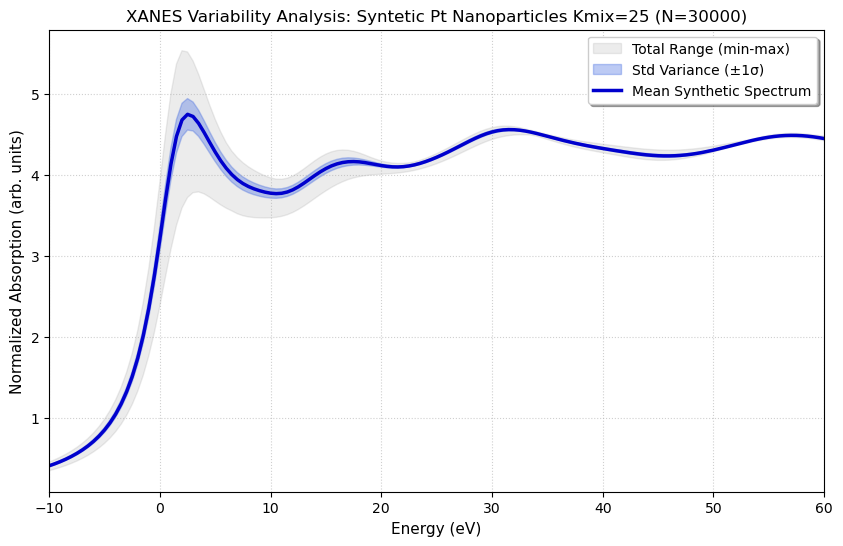

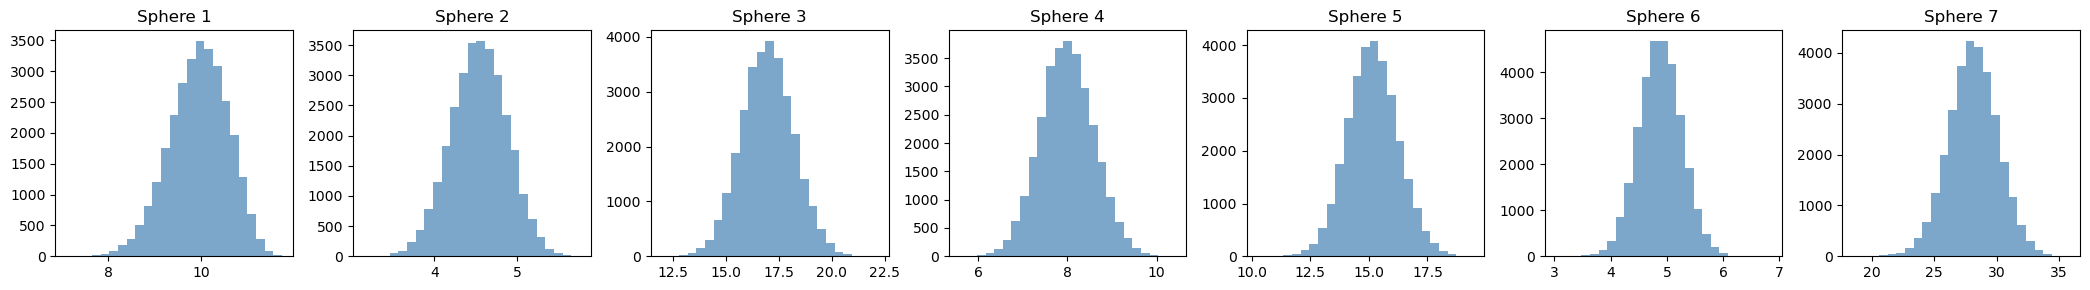

CPU times: total: 17.1 s
Wall time: 9.34 s


In [10]:
%%time

K_mix=25
save_name_cn = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_CN'))
save_name_spec = str(Path(FIG_SAVE_PATH,f'Kmix_{K_mix}_N_samples_{N_SAMPLES}_Spectra_var'))
train_weights = factory.create_synthetic_mix(n_samples=N_SAMPLES, 
                                             k_range=(K_mix, K_mix), 
                                             pool_indices=None)

X_km, y_km = factory.generate_experiment_data(train_weights, aug_params=None)

plot_dataset_variability(X_data=X_km, 
                         energy_grid=factory.energy_grid,
                         foil_spectrum=None,
                         title_suffix=f"Syntetic Pt Nanoparticles Kmix={K_mix}", 
                         save_name=save_name_spec
                        )

plot_cn_distribution(y_matrix=y_km, save_name=save_name_cn)

### Выводы

* При увеличении числа объектов в смеси подструктур очевидным образом падает вариативность спектров.
* Увеличение значения K_mix приводит к нормализации распределений значений CN (это связанно с большим кол-вом подструктур с CN1=CN1Max)
* При строгом K_mix<5 распределение значений координационных для первой сферы заметно отличается от нормального,
при этом разница в "вариативности" данных полученных при k_mix=2 и k_mix=5 незначительна.
* Для сохранения нормальности распределений CN и разнообразия спектров лучше использовать значения K_mix>=5 или диапазон (K_min>1, K_max>=10)